# Replay one experimental game

This notebook replays one Choi 2020 game and shows:

- the replay setup in separate stages
- the actions printed per step
- the directed graph after each recorded state
- multiple replay metrics plotted from a list of observers


## Imports


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import scienceplots

project_root = Path.cwd()
if not (project_root / "network_creation").exists():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from network_creation.core.observability import ObservationSampling
from network_creation.data.choi_2020 import (
    build_replay_simulator,
    list_choi_2020_configs,
    load_choi_2020_normalized_data,
    run_choi_2020_replay_batch,
)
from network_creation.data.choi_2020_references import (
    build_choi_observers,
    load_reference_parameters,
)
from network_creation.observers.grimoire import OBSERVER_GRIMOIRE
from network_creation.plotting.episode_series import plot_episode_series_observer
from network_creation.plotting.graph_history import (
    build_circle_layout,
    plot_graph_history,
)
from network_creation.plotting.reference_values import get_sigmoid_fit_reference_values
from notebooks.utils.plot_sigmoid_fit import plot_sigmoid_fit

ActionPrintObserver = OBSERVER_GRIMOIRE["action_print"]
StateHistoryObserver = OBSERVER_GRIMOIRE["state_history"]

In [2]:
plt.style.use(style="science")

In [15]:
choi_parameters = {
    row.group_size: row
    for row in load_reference_parameters(project_root / "data/choi_2020/parameters.json")
}
metric_observer_names = (
    "density", "indegree", "global_closeness_centrality", "distance",
    "action_count", "hub_persistence", "central_point_of_dominance",
    "triad_census", "centered_mean_welfare", "agent_payoff"
)
metric_observer_settings = {"hub_persistence": {"window_size": 10}}
aggregate_observer_aggregations = {
    "*": ("mean", "std"),
    "density": ("mean", "std", "runs"),
    "central_point_of_dominance": ("mean", "std", "runs"),
    "centered_mean_welfare": ("mean", "std", "runs"),
    "hub_persistence": ("mean", "std", "runs"),
    "agent_payoff": ("mean", "std", "runs"),
}


def make_metric_observers(group_size, aggregations=()):
    parameters = choi_parameters[int(group_size)]
    return build_choi_observers(
        n_agents=int(group_size),
        observer_names=metric_observer_names,
        observation_sampling=ObservationSampling.periodic(1),
        aggregations=aggregations,
        benefit_to_cost_ratio=parameters.benefit_to_cost_ratio,
        distance_discount=parameters.distance_discount,
        settings_by_observer=metric_observer_settings,
    )


AGENT_PAYOFF_PLOT_DIMENSIONS = (
    "highest_degree",
    "second_highest_degree",
    "rest_except_top_two",
)
AGENT_PAYOFF_ROLE_LABELS = {
    "highest_degree": "top 1 degree",
    "second_highest_degree": "top 2 degree",
    "rest_except_top_two": "rest mean",
}
AGENT_PAYOFF_ROLE_COLORS = {
    "highest_degree": "#1f4e79",
    "second_highest_degree": "#c84c09",
    "rest_except_top_two": "#3a7d44",
}


def observer_plot_dimensions(name, observer):
    if name == "agent_payoff":
        return ()
    return getattr(observer, "dimension_names", None) or (None,)


def observer_plot_specs(observers_by_name):
    return [
        (name, observer, dimension)
        for name, observer in observers_by_name.items()
        for dimension in observer_plot_dimensions(name, observer)
    ]


def plot_agent_payoff_roles(observer, axis, *, show_runs=False):
    for dimension_name in AGENT_PAYOFF_PLOT_DIMENSIONS:
        color = AGENT_PAYOFF_ROLE_COLORS[dimension_name]
        plot_episode_series_observer(
            observer=observer,
            ax=axis,
            dimension_name=dimension_name,
            color=color,
            band_color=color,
            label=AGENT_PAYOFF_ROLE_LABELS[dimension_name],
            set_title=False,
            show_runs=show_runs,
        )


## Replay data


In [16]:
data_root = project_root / "data/choi_2020/raw"
available_configs = list_choi_2020_configs(data_root)
available_configs[:5]

(Choi2020ReplayConfig(group_size=10, session_id=1, group_id=1, round_id=2, source_path=PosixPath('/home/hdahmou/Network_creation/data/choi_2020/raw/Linking_10_1/data.csv')),
 Choi2020ReplayConfig(group_size=10, session_id=1, group_id=1, round_id=3, source_path=PosixPath('/home/hdahmou/Network_creation/data/choi_2020/raw/Linking_10_1/data.csv')),
 Choi2020ReplayConfig(group_size=10, session_id=1, group_id=1, round_id=4, source_path=PosixPath('/home/hdahmou/Network_creation/data/choi_2020/raw/Linking_10_1/data.csv')),
 Choi2020ReplayConfig(group_size=10, session_id=1, group_id=1, round_id=5, source_path=PosixPath('/home/hdahmou/Network_creation/data/choi_2020/raw/Linking_10_1/data.csv')),
 Choi2020ReplayConfig(group_size=10, session_id=1, group_id=1, round_id=6, source_path=PosixPath('/home/hdahmou/Network_creation/data/choi_2020/raw/Linking_10_1/data.csv')))

In [17]:
config = available_configs[0]
max_steps = load_choi_2020_normalized_data(config).max_step
config, max_steps

(Choi2020ReplayConfig(group_size=10, session_id=1, group_id=1, round_id=2, source_path=PosixPath('/home/hdahmou/Network_creation/data/choi_2020/raw/Linking_10_1/data.csv')),
 359)

## Observer settings


In [18]:
action_printer = ActionPrintObserver(
    observation_sampling=ObservationSampling.periodic(1),
    print_empty_steps=False,
)
metric_observers_by_name = make_metric_observers(config.group_size)
metric_observers = tuple(metric_observers_by_name.values())
state_history_observer = StateHistoryObserver(
    observation_sampling=ObservationSampling.periodic(1),
    keep_runs=False,
)

(
    action_printer.__class__.__name__,
    list(metric_observers_by_name),
    state_history_observer.__class__.__name__,
)

('ActionPrintObserver',
 ['density',
  'indegree',
  'global_closeness_centrality',
  'distance',
  'action_count',
  'hub_persistence',
  'central_point_of_dominance',
  'triad_census',
  'centered_mean_welfare',
  'agent_payoff'],
 'StateHistoryObserver')

## Build the replay simulator


In [19]:
simulator = build_replay_simulator(
    config=config,
    observers=(action_printer, *metric_observers, state_history_observer),
    max_steps=max_steps,
)

fixed_layout = build_circle_layout(simulator.n_agents)


## Run the replay


In [8]:
simulator.run(n_episodes=1, reset_observers=False)

(
    simulator.n_completed_episodes,
    state_history_observer.steps[-1],
    {observer.__class__.__name__: observer.steps[-1] for observer in metric_observers},
)



step 6
  8: ADD->2

step 7
  2: ADD->4
  3: ADD->5
  6: ADD->4
  8: ADD->3, ADD->4

step 8
  1: ADD->5
  2: ADD->7

step 9
  5: ADD->7
  7: ADD->0
  8: ADD->6
  9: ADD->8

step 10
  8: ADD->0

step 11
  4: ADD->8
  6: DELETE->4

step 12
  1: ADD->4

step 13
  1: DELETE->5
  7: DELETE->0

step 14
  2: DELETE->7, ADD->8

step 15
  2: DELETE->8
  5: ADD->8

step 16
  2: ADD->9

step 17
  5: DELETE->7

step 18
  2: DELETE->9
  3: DELETE->5
  8: ADD->7

step 19
  1: ADD->8
  2: DELETE->4

step 20
  1: DELETE->4
  2: ADD->7

step 22
  2: DELETE->7

step 23
  2: ADD->6

step 24
  9: ADD->4, DELETE->8

step 26
  2: DELETE->6

step 28
  8: ADD->9

step 31
  3: ADD->7
  5: ADD->9

step 32
  3: DELETE->7
  5: DELETE->8

step 34
  5: ADD->8

step 35
  3: ADD->8
  5: DELETE->9

step 36
  2: ADD->5

step 37
  2: DELETE->5

step 39
  2: ADD->1
  3: DELETE->8

step 40
  2: DELETE->1

step 41
  2: ADD->0
  8: DELETE->4

step 42
  2: DELETE->0

step 43
  2: ADD->7
  5: ADD->2

step 44
  2: DELETE->7
  

(1,
 np.int64(359),
 {'DensityObserver': np.int64(359),
  'IndegreeObserver': np.int64(359),
  'GlobalClosenessCentralityObserver': np.int64(359),
  'DistanceObserver': np.int64(359),
  'ActionCountObserver': np.int64(359),
  'HubPersistenceObserver': np.int64(359),
  'CentralPointOfDominanceObserver': np.int64(359),
  'TriadCensusObserver': np.int64(359),
  'CenteredMeanWelfareObserver': np.int64(359),
  'AgentPayoffObserver': np.int64(359)})

In [9]:
metric_observers[-1].values[:25]

array([[ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ],
       [ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ],
       [ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ],
       [ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ],
       [ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ],
       [ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ],
       [ 0.        ,  0.        ,  0.11111111,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        

## Directed graph after each recorded state


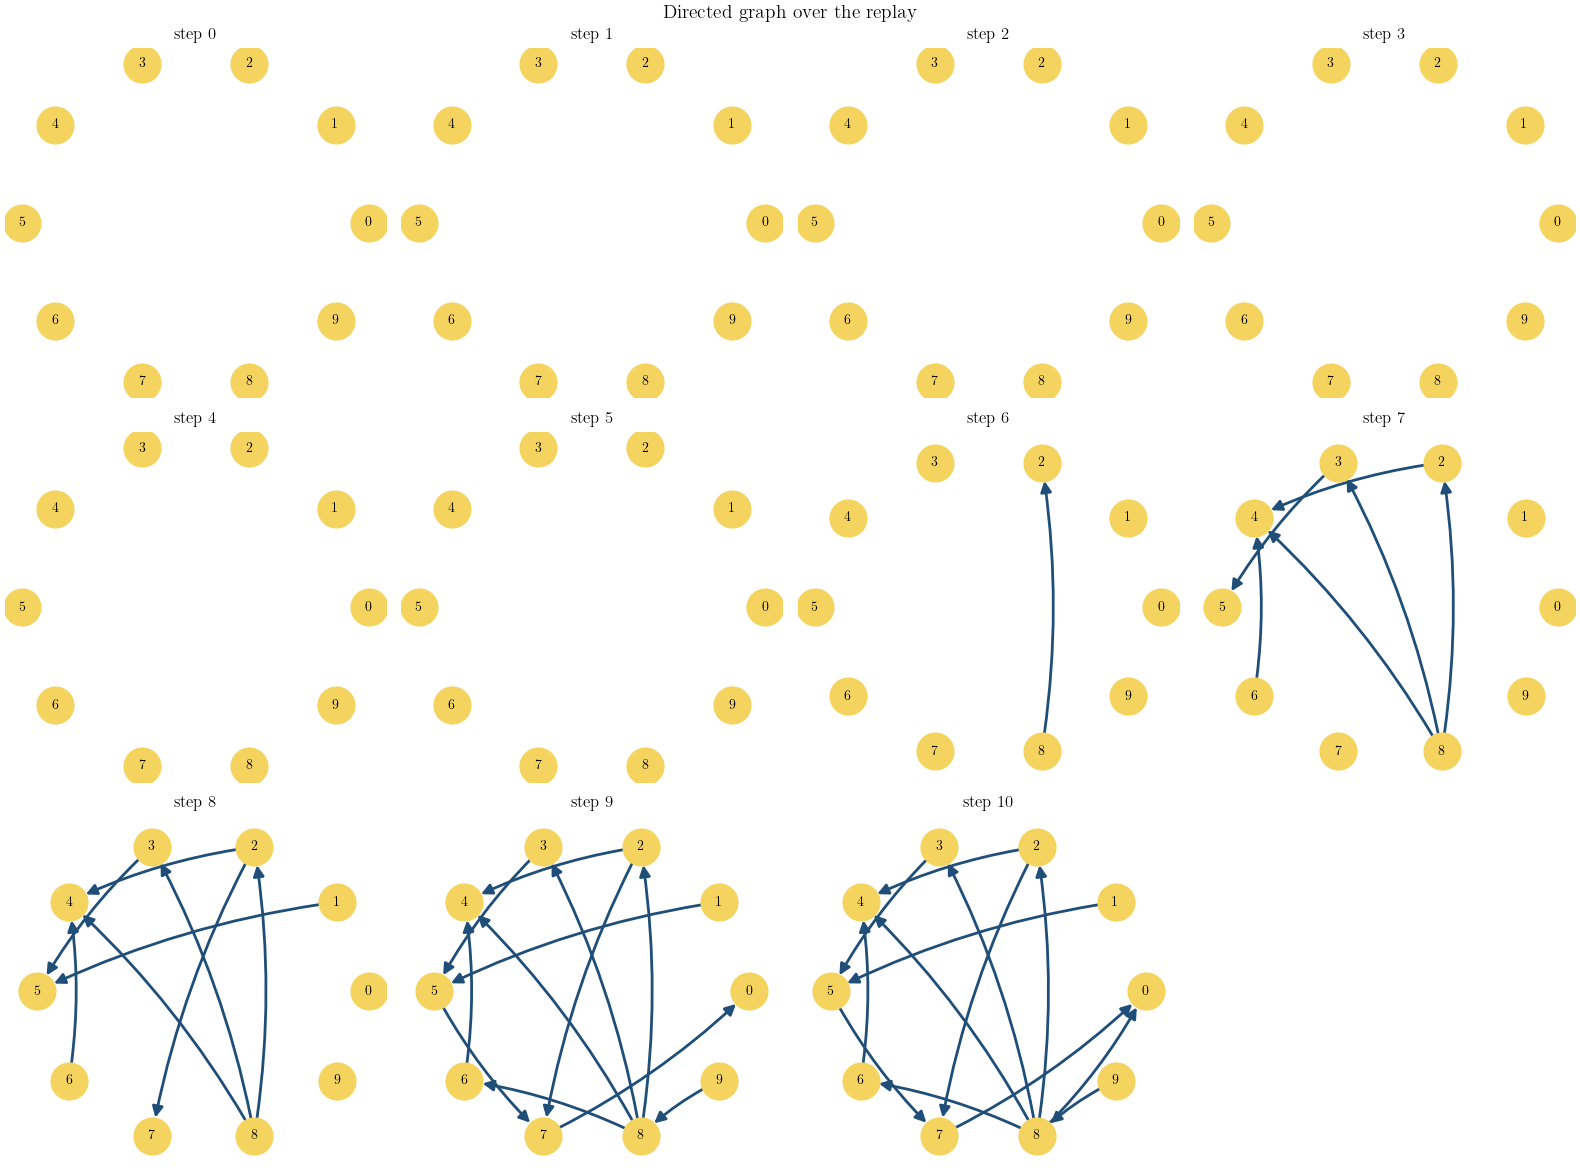

In [10]:
plot_mask = state_history_observer.steps <= 10
plot_graph_history(
    steps=state_history_observer.steps[plot_mask],
    graphs=state_history_observer.graphs[plot_mask],
    layout=fixed_layout,
    figure_title="Directed graph over the replay",
    max_cols=4,
)
plt.show()


## Metrics across the replay


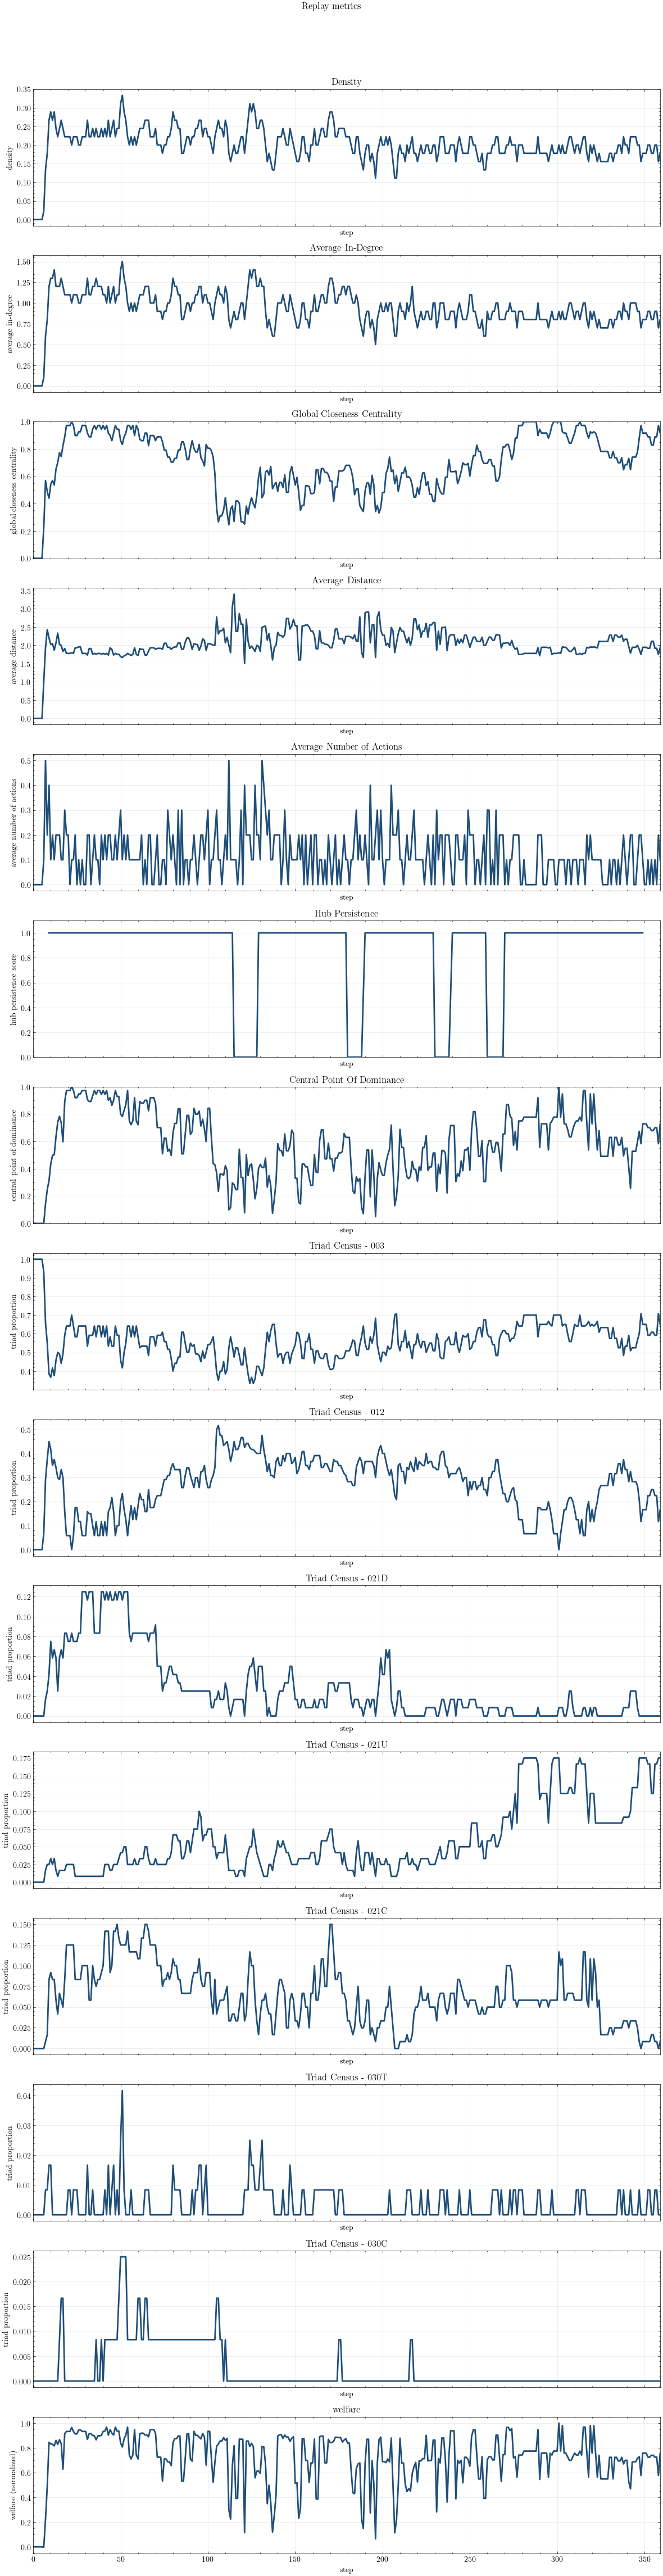

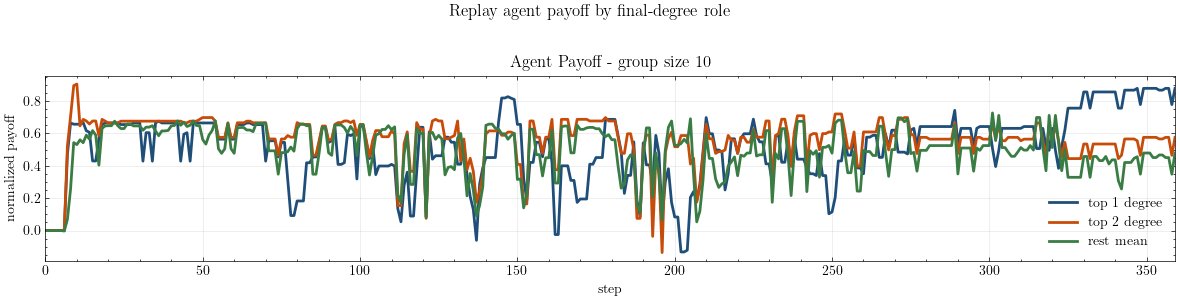

In [11]:
plot_specs = observer_plot_specs(metric_observers_by_name)

figure, axes = plt.subplots(
    len(plot_specs),
    1,
    figsize=(12, 3 * len(plot_specs)),
    squeeze=False,
    sharex=True,
)

for (_, observer, dimension_name), axis in zip(plot_specs, axes.ravel()):
    plot_episode_series_observer(
        observer=observer,
        ax=axis,
        dimension_name=dimension_name,
        set_title=False,
    )
    axis.set_title(
        observer.label if dimension_name is None else f"{observer.label} - {dimension_name}"
    )

figure.suptitle("Replay metrics", y=1.02)
figure.tight_layout()
plt.show()

figure, axis = plt.subplots(figsize=(12, 3), sharex=True)
plot_agent_payoff_roles(
    metric_observers_by_name["agent_payoff"],
    axis
)
axis.set_title(f"Agent Payoff - group size {config.group_size}")
figure.suptitle("Replay agent payoff by final-degree role", y=1.02)
figure.tight_layout()
plt.show()

## Aggregate metrics across group sizes


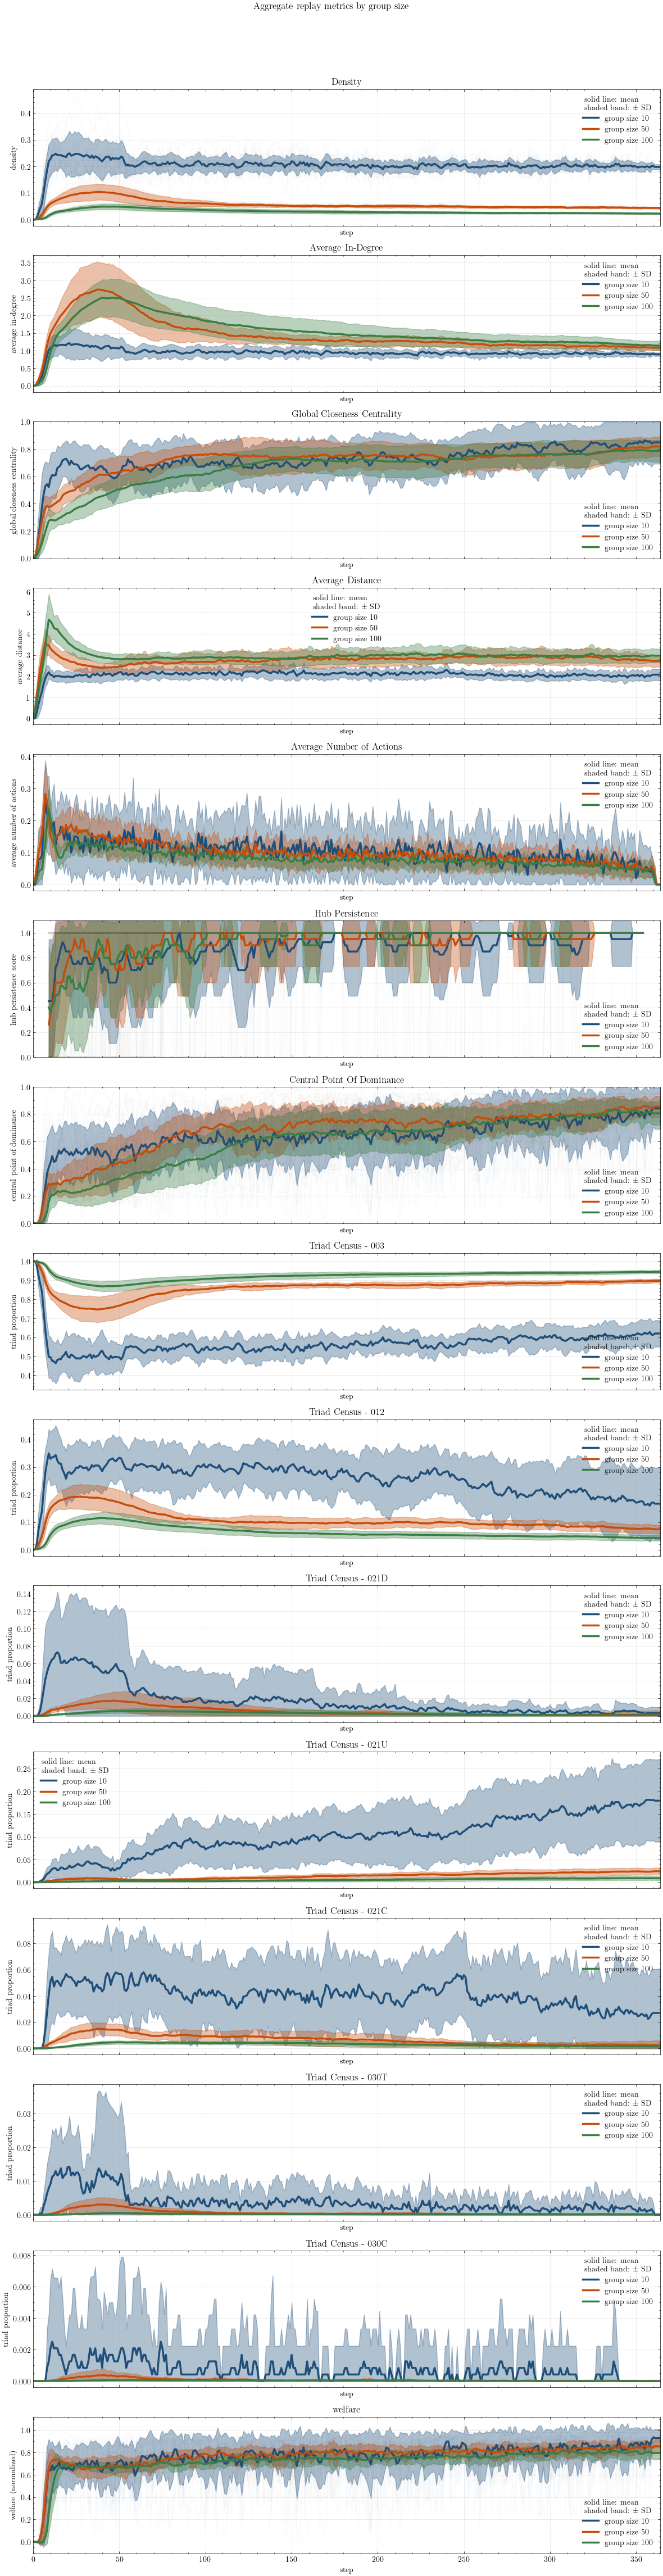

In [20]:
group_sizes = sorted(choi_parameters)
group_colors = ["#1f4e79", "#c84c09", "#3a7d44"]

max_steps = 364
aggregate_metrics_by_group_size = {}
for group_size in group_sizes:
    group_configs = tuple(
        replay_config
        for replay_config in available_configs
        if replay_config.group_size == group_size
    )
    aggregate_metric_observers_by_name = make_metric_observers(
        group_size, aggregate_observer_aggregations
    )
    run_choi_2020_replay_batch(
        configs=group_configs,
        observers=tuple(aggregate_metric_observers_by_name.values()),
        max_steps=max_steps,
    )
    aggregate_metrics_by_group_size[group_size] = aggregate_metric_observers_by_name

reference_observers_by_name = aggregate_metrics_by_group_size[group_sizes[0]]
plot_specs = observer_plot_specs(reference_observers_by_name)

figure, axes = plt.subplots(
    len(plot_specs),
    1,
    figsize=(12, 3 * len(plot_specs)),
    squeeze=False,
    sharex=True,
)

for (observer_name, reference_observer, dimension_name), axis in zip(
    plot_specs,
    axes.ravel(),
):
    for group_size, color in zip(group_sizes, group_colors):
        observer = aggregate_metrics_by_group_size[group_size][observer_name]
        plot_episode_series_observer(
            observer=observer,
            ax=axis,
            dimension_name=dimension_name,
            color=color,
            band_color=color,
            label=f"group size {group_size}",
            set_title=False,
            show_runs=True,
        )
    axis.set_title(
        reference_observer.label
        if dimension_name is None
        else f"{reference_observer.label} - {dimension_name}"
    )

figure.suptitle("Aggregate replay metrics by group size", y=1.02)
figure.tight_layout()
plt.show()

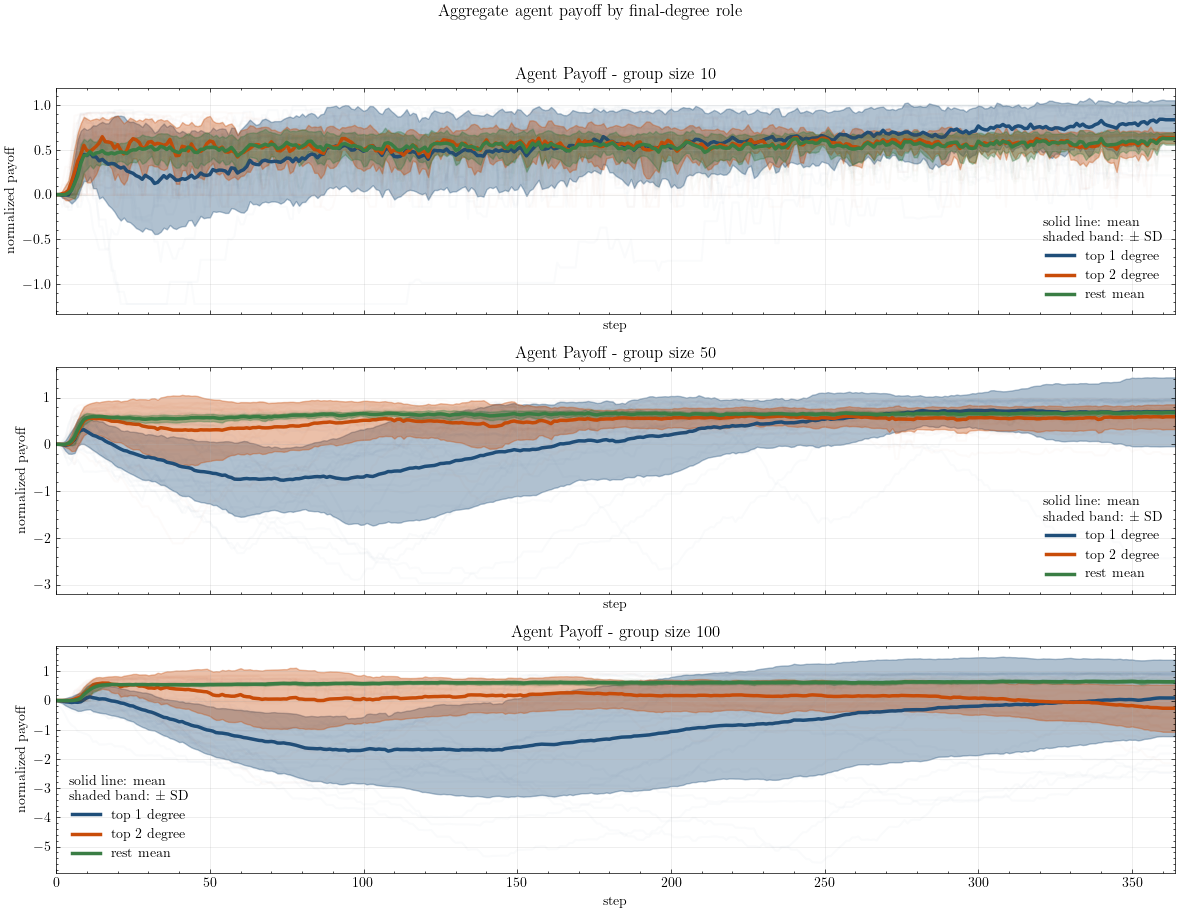

In [21]:
figure, axes = plt.subplots(
    len(group_sizes),
    1,
    figsize=(12, 3 * len(group_sizes)),
    squeeze=False,
    sharex=True,
)

for group_size, axis in zip(group_sizes, axes.ravel()):
    plot_agent_payoff_roles(
        aggregate_metrics_by_group_size[group_size]["agent_payoff"],
        axis,
        show_runs=True,
    )
    axis.set_title(f"Agent Payoff - group size {group_size}")

figure.suptitle("Aggregate agent payoff by final-degree role", y=1.02)
figure.tight_layout()
plt.show()

### Raw timelines and sigmoid fits

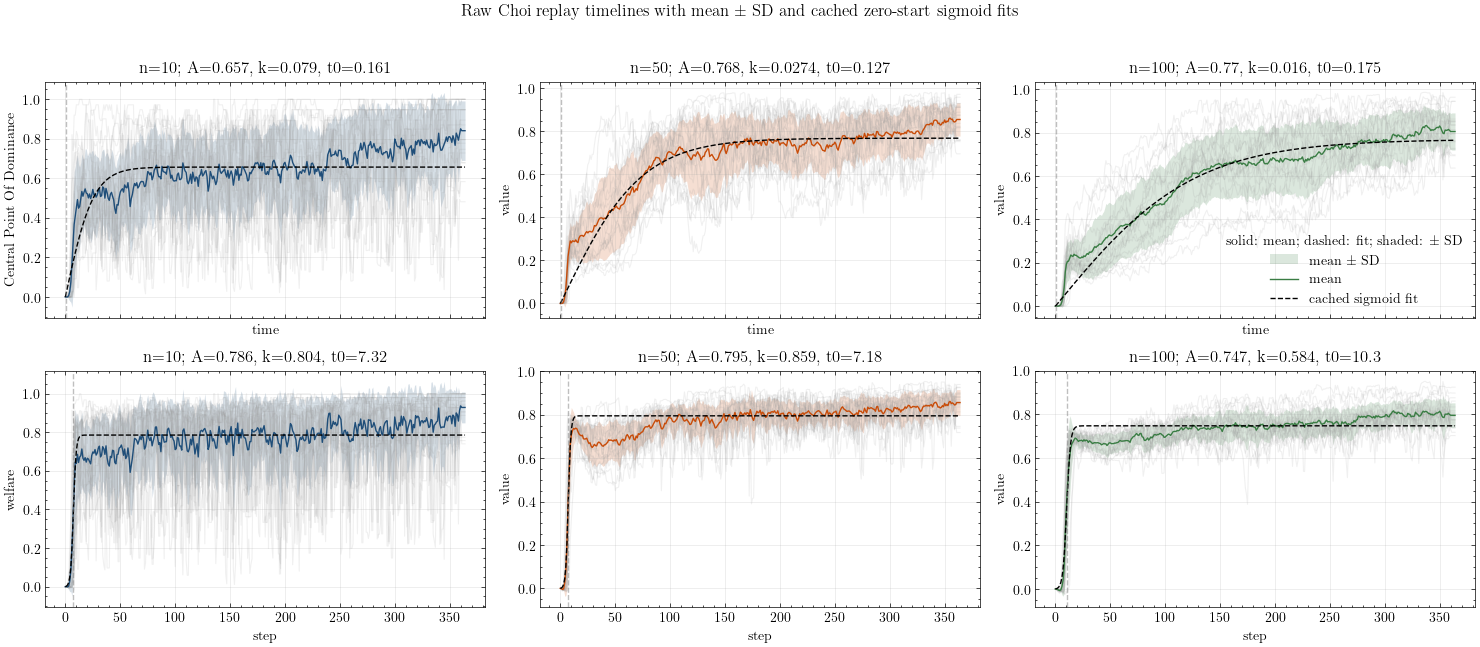

In [22]:
sigmoid_observer_names = (
    "central_point_of_dominance",
    "centered_mean_welfare",
)
max_raw_timelines_per_panel = 80


def cached_sigmoid_parameters(observer_name, group_size):
    references = get_sigmoid_fit_reference_values(
        f"{observer_name}.mean",
        n_agents=int(group_size),
    )
    try:
        return tuple(
            float(references[parameter_name]["choi2020"])
            for parameter_name in ("A", "k", "t0")
        )
    except KeyError:
        return None

figure, axes = plt.subplots(
    len(sigmoid_observer_names),
    len(group_sizes),
    figsize=(5 * len(group_sizes), 3.2 * len(sigmoid_observer_names)),
    squeeze=False,
    sharex=True,
)

for row, observer_name in enumerate(sigmoid_observer_names):
    reference_observer = aggregate_metrics_by_group_size[group_sizes[0]][observer_name]
    for col, (group_size, color) in enumerate(zip(group_sizes, group_colors)):
        observer = aggregate_metrics_by_group_size[group_size][observer_name]
        result = observer.get()
        t = np.asarray(result.steps, dtype=float)
        mean = np.asarray(result.outputs["mean"], dtype=float).reshape(-1)
        std = np.asarray(result.outputs["std"], dtype=float).reshape(-1)
        params = cached_sigmoid_parameters(observer_name, group_size)

        axis = axes[row, col]
        runs = result.outputs.get("runs", ())
        if runs:
            run_indices = np.linspace(
                0,
                len(runs) - 1,
                min(max_raw_timelines_per_panel, len(runs)),
                dtype=int,
            )
            for run_index in run_indices:
                raw = np.asarray(runs[run_index], dtype=float).reshape(-1)
                axis.plot(t, raw, color="0.6", alpha=0.14, linewidth=0.8)

        axis.fill_between(
            t,
            mean - std,
            mean + std,
            color=color,
            alpha=0.18,
            linewidth=0,
            label="mean ± SD",
        )

        if params is None:
            axis.plot(t, mean, color=color, linewidth=2.0, label="mean")
            axis.set_title(f"n={group_size}; missing cached fit")
        else:
            A, k, t0 = params
            plot_sigmoid_fit(
                mean,
                A,
                k,
                t0,
                t=t,
                ax=axis,
                data_label="mean",
                fit_label="cached sigmoid fit",
                data_color=color,
                fit_color="black",
                fit_linestyle="--",
                show_legend=False,
            )
            axis.set_title(f"n={group_size}; A={A:.3g}, k={k:.3g}, t0={t0:.3g}")
        if col == 0:
            axis.set_ylabel(reference_observer.label)
        if row == len(sigmoid_observer_names) - 1:
            axis.set_xlabel("step")
        if row == 0 and col == len(group_sizes) - 1:
            axis.legend(loc="best", title="solid: mean; dashed: fit; shaded: ± SD")

figure.suptitle("Raw Choi replay timelines with mean ± SD and cached zero-start sigmoid fits", y=1.02)
figure.tight_layout()
plt.show()